In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy.stats import norm, shapiro, ttest_ind, mannwhitneyu, levene, t, ttest_rel, wilcoxon, probplot


Obtener datos Grupo Control

In [2]:
# Obtener datos de grupo control

'https://docs.google.com/spreadsheets/d/1hLxzLvhqROPelBWYukI6BLQLRNKlE3G5/edit?gid=866666347#gid=866666347'
sheet_id = "1hLxzLvhqROPelBWYukI6BLQLRNKlE3G5"
gid = "866666347"
url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=xlsx&gid={gid}"
file = pd.read_excel(url)
grupo_control = file[file["Grupo"] == 'Control']
grupo_control = grupo_control.drop(columns=['Marca temporal', 'Nombre'])

grupo_control.head()

,Grupo,Test,1. ¿No te das cuenta de lo estúpido que eres?,"2. No se me da bien esto. Simplemente, no sé cómo hacer que te sientas mejor.",3. ¿Qué está pasando? Necesitamos hablar.,4. No te sirvo de ayuda. Nunca sé qué decir.,5. Tenemos que concretar eso.,6. Quisiera que pudieramos evitar todo este asunto.,7. Vamos a hablar sobre esto y encontrar una solución.,8. ¡Cállate! ¡No tienes razón! No voy a escucharte,9. ¡Es tu culpa tuya! Y no voy a ayudarte,10. Harás lo que yo te digo. ¡Te voy a obligar!,11. Funcionará si trabajamos juntos.,12. Trabajaremos para sacar esto adelante.,"13. De acuerdo, me rindo, lo que tú quieras.",14. No quiero hacer esto nunca más. Vamos cada uno por su lado.,"15. Esto no va a ninguna parte, olvidemos todo el asunto. ¿de acuerdo?","16. Si no quieres hacerlo, olvídalo; ya se lo pediré a algún otro.",17. Necesitamos concretar juntos cuál es el problema.,18. No puedes hacer nada. Apártate de mi camino y déjame hacerlo.
60,Control,Pretest,1,2,3,2,1,3,4,1,1,1,3,4,4,1,1,3,5,1
61,Control,Postest,1,2,4,5,3,1,3,1,2,1,4,3,5,4,3,3,2,3
62,Control,Pretest,2,3,4,2,2,2,3,2,3,2,5,3,2,2,3,2,5,2
63,Control,Postest,1,2,3,3,2,3,1,4,2,3,2,3,2,2,3,1,2,2
64,Control,Pretest,2,3,2,2,2,3,5,2,3,5,2,2,3,5,2,2,1,1


Obtener datos Grupo Experimental

In [3]:
'https://docs.google.com/spreadsheets/d/1XE4HPULK9j5NMOfBo1lkc_UlcT1F9_vT/edit?gid=1421523016#gid=1421523016'
id_sheet = '1XE4HPULK9j5NMOfBo1lkc_UlcT1F9_vT'
gid = '1421523016'
url = f'https://docs.google.com/spreadsheets/d/{id_sheet}/export?format=xlsx&gid={gid}'
file = pd.read_excel(url)
file.head()

,Marca temporal,Marca temporal 2,Marca temporal 3,Test,1. ¿No te das cuenta de lo estúpido que eres?,"2. No se me da bien esto. Simplemente, no sé cómo hacer que te sientas mejor.",3. ¿Qué está pasando? Necesitamos hablar.,4. No te sirvo de ayuda. Nunca sé qué decir.,5. Tenemos que concretar eso.,6. Quisiera que pudieramos evitar todo este asunto.,...,9. ¡Es tu culpa tuya! Y no voy a ayudarte,10. Harás lo que yo te digo. ¡Te voy a obligar!,11. Funcionará si trabajamos juntos.,12. Trabajaremos para sacar esto adelante.,"13. De acuerdo, me rindo, lo que tú quieras.",14. No quiero hacer esto nunca más. Vamos cada uno por su lado.,"15. Esto no va a ninguna parte, olvidemos todo el asunto. ¿de acuerdo?","16. Si no quieres hacerlo, olvídalo; ya se lo pediré a algún otro.",17. Necesitamos concretar juntos cuál es el problema.,18. No puedes hacer nada. Apártate de mi camino y déjame hacerlo.
0,2026-09-26 15:01:21.553,2026-09-26 15:01:21.553,2026-09-26 15:01:21.553,Pretest,2 a veces,2 a veces,3 con cierta frecuencia,2 a veces,3 con cierta frecuencia,2 a veces,...,3 con cierta frecuencia,2 a veces,3 con cierta frecuencia,2 a veces,2 a veces,2 a veces,2 a veces,3 con cierta frecuencia,3 con cierta frecuencia,3 con cierta frecuencia
1,2026-09-26 15:03:20.684,2026-09-26 15:03:20.684,2026-09-26 15:03:20.684,Postest,2 a veces,2 a veces,4 muy frecuentemente,1 nunca,2 a veces,2 a veces,...,2 a veces,2 a veces,3 con cierta frecuencia,3 con cierta frecuencia,3 con cierta frecuencia,2 a veces,3 con cierta frecuencia,2 a veces,3 con cierta frecuencia,3 con cierta frecuencia
2,2026-09-26 15:05:26.455,2026-09-26 15:05:26.455,2026-09-26 15:05:26.455,Pretest,1 nunca,5 casi siempre,2 a veces,5 casi siempre,1 nunca,2 a veces,...,1 nunca,1 nunca,1 nunca,2 a veces,1 nunca,5 casi siempre,3 con cierta frecuencia,4 muy frecuentemente,2 a veces,1 nunca
3,2026-09-26 15:06:43.350,2026-09-26 15:06:43.350,2026-09-26 15:06:43.350,Postest,3 con cierta frecuencia,5 casi siempre,4 muy frecuentemente,5 casi siempre,2 a veces,3 con cierta frecuencia,...,1 nunca,1 nunca,2 a veces,5 casi siempre,2 a veces,4 muy frecuentemente,3 con cierta frecuencia,2 a veces,3 con cierta frecuencia,5 casi siempre
4,2026-09-26 15:08:55.322,2026-09-26 15:08:55.322,2026-09-26 15:08:55.322,Pretest,1 nunca,3 con cierta frecuencia,5 casi siempre,2 a veces,2 a veces,3 con cierta frecuencia,...,2 a veces,1 nunca,5 casi siempre,5 casi siempre,1 nunca,3 con cierta frecuencia,3 con cierta frecuencia,2 a veces,5 casi siempre,1 nunca


In [4]:
# Limpiar grupo experimental

# Eliminar marcas temporales
grupo_experimental = file.drop(columns=["Marca temporal", "Marca temporal 2", "Marca temporal 3"])

# Agregar columna grupo con el valor experimental por defecto y posicionar en la primera columna
grupo_experimental['Grupo'] = "Experimental"
grupo_experimental.insert(0, 'Grupo', grupo_experimental.pop('Grupo'))

# Reemplazar valores
reemplazar_valores = {
    "1 nunca": 1,
    "2 a veces": 2,
    "3 con cierta frecuencia": 3,
    "4 muy frecuentemente": 4,
    "5 casi siempre": 5,
}
for column in grupo_experimental.columns:
    grupo_experimental[column] = grupo_experimental[column].replace(reemplazar_valores)

grupo_experimental.head()

C:\Users\crist\AppData\Local\Temp\ipykernel_19092\402643191.py:19: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  grupo_experimental[column] = grupo_experimental[column].replace(reemplazar_valores)


,Grupo,Test,1. ¿No te das cuenta de lo estúpido que eres?,"2. No se me da bien esto. Simplemente, no sé cómo hacer que te sientas mejor.",3. ¿Qué está pasando? Necesitamos hablar.,4. No te sirvo de ayuda. Nunca sé qué decir.,5. Tenemos que concretar eso.,6. Quisiera que pudieramos evitar todo este asunto.,7. Vamos a hablar sobre esto y encontrar una solución.,8. ¡Cállate! ¡No tienes razón! No voy a escucharte,9. ¡Es tu culpa tuya! Y no voy a ayudarte,10. Harás lo que yo te digo. ¡Te voy a obligar!,11. Funcionará si trabajamos juntos.,12. Trabajaremos para sacar esto adelante.,"13. De acuerdo, me rindo, lo que tú quieras.",14. No quiero hacer esto nunca más. Vamos cada uno por su lado.,"15. Esto no va a ninguna parte, olvidemos todo el asunto. ¿de acuerdo?","16. Si no quieres hacerlo, olvídalo; ya se lo pediré a algún otro.",17. Necesitamos concretar juntos cuál es el problema.,18. No puedes hacer nada. Apártate de mi camino y déjame hacerlo.
0,Experimental,Pretest,2,2,3,2,3,2,3,3,3,2,3,2,2,2,2,3,3,3
1,Experimental,Postest,2,2,4,1,2,2,2,2,2,2,3,3,3,2,3,2,3,3
2,Experimental,Pretest,1,5,2,5,1,2,2,1,1,1,1,2,1,5,3,4,2,1
3,Experimental,Postest,3,5,4,5,2,3,4,1,1,1,2,5,2,4,3,2,3,5
4,Experimental,Pretest,1,3,5,2,2,3,5,1,2,1,5,5,1,3,3,2,5,1


**Aplicar instrumento conflictalk

In [5]:
# Unir los datos del grupo experimental y control
datos_conflictalk = pd.concat([grupo_control, grupo_experimental])
datos_conflictalk

,Grupo,Test,1. ¿No te das cuenta de lo estúpido que eres?,"2. No se me da bien esto. Simplemente, no sé cómo hacer que te sientas mejor.",3. ¿Qué está pasando? Necesitamos hablar.,4. No te sirvo de ayuda. Nunca sé qué decir.,5. Tenemos que concretar eso.,6. Quisiera que pudieramos evitar todo este asunto.,7. Vamos a hablar sobre esto y encontrar una solución.,8. ¡Cállate! ¡No tienes razón! No voy a escucharte,9. ¡Es tu culpa tuya! Y no voy a ayudarte,10. Harás lo que yo te digo. ¡Te voy a obligar!,11. Funcionará si trabajamos juntos.,12. Trabajaremos para sacar esto adelante.,"13. De acuerdo, me rindo, lo que tú quieras.",14. No quiero hacer esto nunca más. Vamos cada uno por su lado.,"15. Esto no va a ninguna parte, olvidemos todo el asunto. ¿de acuerdo?","16. Si no quieres hacerlo, olvídalo; ya se lo pediré a algún otro.",17. Necesitamos concretar juntos cuál es el problema.,18. No puedes hacer nada. Apártate de mi camino y déjame hacerlo.
60,Control,Pretest,1,2,3,2,1,3,4,1,1,1,3,4,4,1,1,3,5,1
61,Control,Postest,1,2,4,5,3,1,3,1,2,1,4,3,5,4,3,3,2,3
62,Control,Pretest,2,3,4,2,2,2,3,2,3,2,5,3,2,2,3,2,5,2
63,Control,Postest,1,2,3,3,2,3,1,4,2,3,2,3,2,2,3,1,2,2
64,Control,Pretest,2,3,2,2,2,3,5,2,3,5,2,2,3,5,2,2,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55,Experimental,Postest,3,2,1,1,3,2,4,2,1,1,3,5,3,2,1,3,3,2
56,Experimental,Pretest,3,3,2,1,1,3,2,1,2,1,3,2,2,1,1,1,1,2
57,Experimental,Postest,2,2,2,2,2,2,2,1,3,1,3,2,3,3,2,2,3,1
58,Experimental,Pretest,1,3,4,3,4,5,5,1,1,1,4,4,2,2,3,1,4,1


In [6]:

estilos = {
    "cooperativo": [3, 5, 7, 11, 12, 17],
    "evitativo": [2, 4, 6, 13, 14, 15],
    "agresivo": [1, 8, 9, 10, 16, 18]
}

for estilo in estilos:
    # dar con la columnas correspondiente real
    x = [i+1 for i in estilos[estilo]]
    
    # Sumar columnas correspondientes
    datos_conflictalk[estilo] = datos_conflictalk.iloc[:, x].sum(axis=1)

datos_estilos = datos_conflictalk[['Grupo', 'Test'] + list(estilos)].copy()
datos_estilos

,Grupo,Test,cooperativo,evitativo,agresivo
60,Control,Pretest,20,13,8
61,Control,Postest,19,20,11
62,Control,Pretest,22,14,13
63,Control,Postest,13,15,13
64,Control,Pretest,14,18,15
...,...,...,...,...,...
55,Experimental,Postest,19,11,12
56,Experimental,Pretest,11,11,10
57,Experimental,Postest,14,14,10
58,Experimental,Pretest,25,18,6


Estadísticos descriptivos

In [7]:
tabla_descriptivos = datos_estilos.groupby(['Grupo', 'Test'])[list(estilos.keys())].agg(['count', 'mean', 'std' ]).round(2)
tabla_descriptivos

cooperativo              evitativo              agresivo  \
                           count   mean   std     count   mean   std    count   
Grupo        Test                                                               
Control      Postest          30  17.77  5.96        30  14.53  5.27       30   
             Pretest          30  17.43  5.33        30  14.30  4.63       30   
Experimental Postest          30  16.33  4.12        30  13.60  4.01       30   
             Pretest          30  16.67  4.96        30  13.57  4.51       30   

                                   
                       mean   std  
Grupo        Test                  
Control      Postest  11.90  4.82  
             Pretest  12.50  4.54  
Experimental Postest  10.37  3.68  
             Pretest  10.33  3.89

In [8]:
# Aplanar el MultiIndex de columnas
tabla_plot = tabla_descriptivos.copy()
tabla_plot.columns = ['_'.join(col) for col in tabla_plot.columns]
tabla_plot = tabla_plot.reset_index()

# Pasar a formato largo (una fila por Grupo, Test, Estilo)
tabla_long = tabla_plot.melt(
    id_vars=['Grupo', 'Test'],
    value_vars=['cooperativo_mean', 'evitativo_mean', 'agresivo_mean'],
    var_name='Estilo',
    value_name='Promedio'
)
tabla_long['Estilo'] = tabla_long['Estilo'].str.replace('_mean', '')

#
colores = {
    'cooperativo': "#3E3298",
    'evitativo': "#6958EA",
    'agresivo': "#0B0444"
}



In [9]:
fig = px.bar(
    tabla_long,
    x='Grupo',
    y='Promedio',
    color='Estilo',
    barmode='group',
    facet_col='Test',  # una faceta por Control/Experimental
    title='Promedio de estilos de conflicto por grupo',
    color_discrete_map=colores,
    category_orders={
        'Test': ['Pretest', "Postest"]
    }
)
fig.show()

In [10]:
fig = px.bar(
    tabla_long,
    x='Test',
    y='Promedio',
    color='Estilo',
    barmode='group',
    facet_col='Grupo',  # una faceta por Control/Experimental
    title='Promedio de estilos de conflicto por test',
    color_discrete_map=colores,
    category_orders={
        'Test': ['Pretest', "Postest"]
    }
)
fig.show()

In [11]:
tabla_diff_grupo = tabla_long.pivot_table(
    index=['Grupo', 'Estilo'],
    columns='Test',
    values='Promedio'
).reset_index()

tabla_diff_grupo['Diferencia'] = tabla_diff_grupo['Postest'] - tabla_diff_grupo['Pretest']

tabla_diff_grupo = tabla_diff_grupo[['Grupo', 'Estilo', 'Pretest', 'Postest', 'Diferencia']]

tabla_diff_grupo

Test,Grupo,Estilo,Pretest,Postest,Diferencia
0,Control,agresivo,12.50,11.90,-0.60
1,Control,cooperativo,17.43,17.77,0.34
2,Control,evitativo,14.30,14.53,0.23
3,Experimental,agresivo,10.33,10.37,0.04
4,Experimental,cooperativo,16.67,16.33,-0.34
5,Experimental,evitativo,13.57,13.60,0.03


In [12]:
# Ordenar la categoria del test
tabla_long['Test'] = pd.Categorical(
    tabla_long['Test'],
    categories=['Pretest', 'Postest'],
    ordered=True
)

tabla_diff_test = tabla_long.pivot_table(
    index=['Test', 'Estilo'],
    columns='Grupo',
    values='Promedio'
).reset_index()

tabla_diff_test['Diferencia'] = tabla_diff_test['Experimental'] - tabla_diff_test['Control']

tabla_diff_test = tabla_diff_test[['Test', 'Estilo', 'Control', 'Experimental', 'Diferencia']]

tabla_diff_test

C:\Users\crist\AppData\Local\Temp\ipykernel_19092\1608946572.py:8: FutureWarning:

The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior



Grupo,Test,Estilo,Control,Experimental,Diferencia
0,Pretest,agresivo,12.50,10.33,-2.17
1,Pretest,cooperativo,17.43,16.67,-0.76
2,Pretest,evitativo,14.30,13.57,-0.73
3,Postest,agresivo,11.90,10.37,-1.53
4,Postest,cooperativo,17.77,16.33,-1.44
5,Postest,evitativo,14.53,13.60,-0.93


In [13]:
fig = px.bar(
    tabla_diff_grupo,
    x='Estilo',
    y='Diferencia',
    color='Estilo',
    facet_col='Grupo',
    color_discrete_map=colores,
    category_orders={
        'Estilo': estilos.keys()
    },
    title="Diferencias de medias por grupo"
)
fig.add_hline(y=0, line_dash='dash', line_color='gray')
fig.update_layout(showlegend=False)
fig.show()

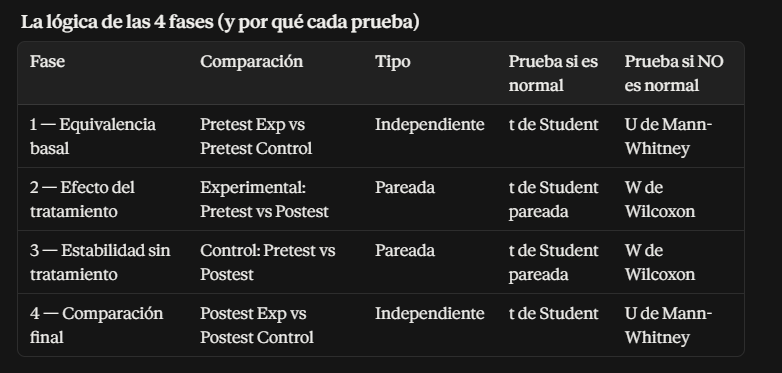

Evaluación de resultados
1. Equivalencia basal
   
   Comparar los grupos antes de la intervención.
2. Cambio en el grupo experimental
   
   Analizar las diferencias entre Pretest y Postest.
3. Estabilidad del grupo control
   
   Analizar las diferencias entre Pretest y Postest.
4. Comparación final
   
   Comparar los grupos después de la intervención.
5. Efecto diferencial de la intervención
   
   Comparar directamente los cambios entre el grupo experimental y el control mediante Grupo × Tiempo o un análisis equivalente.

# 1. Equivalencia <br>
**Comparación:** Pretest (Control | Experimental) <br>
**Intención:** Evaluar las diferencias iniciales

H₀: Los datos provienen de una distribución normal

H₁: Los datos no provienen de una distribución normal

In [14]:
tabla_datos = datos_estilos.melt(
    id_vars=[
        'Grupo', 
        'Test'
    ],
    value_vars=['cooperativo', 'evitativo', 'agresivo'],
    var_name='Estilo',
    value_name='Puntaje'
)
# Ordenar categorias
tabla_datos['Estilo'] = pd.Categorical(
    tabla_datos['Estilo'],
    categories=['cooperativo', 'evitativo', 'agresivo'],
)
tabla_datos['Test'] = pd.Categorical(
    tabla_datos['Test'],
    categories=['Pretest', 'Postest'],
)
tabla_datos['Grupo'] = pd.Categorical(
    tabla_datos['Grupo'],
    categories=['Experimental', 'Control'],
)
alpha = 0.05

# Filtrar únicamente los datos del Pretest
datos_pretest = tabla_datos[
    tabla_datos['Test']
    .astype(str)
    .str.strip()
    .str.lower()
    .eq('pretest')
].copy()

# Normalizar nombres de las categorías
datos_pretest['Estilo'] = (
    datos_pretest['Estilo'].astype(str).str.strip().str.lower()
)
datos_pretest['Grupo'] = (
    datos_pretest['Grupo'].astype(str).str.strip().str.lower()
)
datos_pretest['Test'] = (
    datos_pretest['Test'].astype(str).str.strip().str.lower()
)

resultados = []

# Agrupar por Estilo, Grupo y momento de evaluación
for (estilo, grupo_nombre, test), grupo in datos_pretest.groupby(
    ['Estilo', 'Grupo', 'Test'],
    observed=True
):

    datos = grupo['Puntaje'].dropna().to_numpy()

    N = len(datos)

    # Estadísticos descriptivos
    media = np.mean(datos) if N > 0 else np.nan

    desviacion = (
        np.std(datos, ddof=1)
        if N >= 2
        else np.nan
    )

    # Calcular Shapiro-Wilk
    if N >= 3:
        resultado_shapiro = shapiro(datos)
        W = resultado_shapiro.statistic
        pvalue = resultado_shapiro.pvalue
    else:
        W = np.nan
        pvalue = np.nan

    # Calcular IC del 95 % para la media
    if N >= 2:

        gl = N - 1

        t_critico = t.ppf(
            1 - alpha / 2,
            gl
        )

        error_estandar = desviacion / np.sqrt(N)

        margen_error = t_critico * error_estandar

        ic_inferior = media - margen_error
        ic_superior = media + margen_error

    else:
        ic_inferior = np.nan
        ic_superior = np.nan

    # Decisión de normalidad
    if pd.isna(pvalue):
        decision = 'No calculable'
        distribucion = 'No determinada'

    elif pvalue > alpha:
        decision = 'No se rechaza H₀'
        distribucion = 'Normal'

    else:
        decision = 'Se rechaza H₀'
        distribucion = 'No normal'

    # Guardar resultados
    resultados.append({
        'Estilo': estilo.capitalize(),
        'Test': test.capitalize(),
        'Grupo': grupo_nombre.capitalize(),
        'N': N,
        'Media': media,
        'Desviación Estandar': desviacion,
        'Prueba': 'Shapiro-Wilk',
        'IC 95% inferior': ic_inferior,
        'IC 95% superior': ic_superior,
        'α': alpha,
        'p-value': pvalue,
        'W': W,
        'Resultado hipótesis': decision,
        'Distribución': distribucion
    })


# Crear DataFrame
tabla_normalidad = pd.DataFrame(resultados)

# Ordenar los resultados
orden_grupo = pd.CategoricalDtype(
    categories=['Experimental', 'Control'],
    ordered=True
)
tabla_normalidad['Grupo'] = tabla_normalidad['Grupo'].astype(orden_grupo)

orden_estilos = pd.CategoricalDtype(
    categories=['Cooperativo', 'Evitativo', 'Agresivo'],
    ordered=True
)
tabla_normalidad['Estilo'] = tabla_normalidad['Estilo'].astype(orden_estilos)

tabla_normalidad = tabla_normalidad.sort_values(
    ['Estilo', 'Grupo', 'Test']
).reset_index(drop=True)


# Mostrar tabla
tabla_normalidad.style.format({
    'Media': '{:.3f}',
    'Desviación Estandar': '{:.3f}',
    'IC 95% inferior': '{:.3f}',
    'IC 95% superior': '{:.3f}',
    'α': '{:.2f}',
    'p-value': '{:.4f}',
    'W': '{:.4f}'
})

,Estilo,Test,Grupo,N,Media,Desviación Estandar,Prueba,IC 95% inferior,IC 95% superior,α,p-value,W,Resultado hipótesis,Distribución
0,Cooperativo,Pretest,Experimental,30,16.667,4.964,Shapiro-Wilk,14.813,18.520,0.05,0.6180,0.9728,No se rechaza H₀,Normal
1,Cooperativo,Pretest,Control,30,17.433,5.335,Shapiro-Wilk,15.441,19.425,0.05,0.1416,0.9471,No se rechaza H₀,Normal
2,Evitativo,Pretest,Experimental,30,13.567,4.508,Shapiro-Wilk,11.883,15.250,0.05,0.5134,0.9690,No se rechaza H₀,Normal
3,Evitativo,Pretest,Control,30,14.300,4.632,Shapiro-Wilk,12.570,16.030,0.05,0.3024,0.9596,No se rechaza H₀,Normal
4,Agresivo,Pretest,Experimental,30,10.333,3.889,Shapiro-Wilk,8.881,11.786,0.05,0.0005,0.8473,Se rechaza H₀,No normal
5,Agresivo,Pretest,Control,30,12.500,4.539,Shapiro-Wilk,10.805,14.195,0.05,0.0202,0.9153,Se rechaza H₀,No normal


In [15]:
alpha = 0.05

estilos = ['cooperativo', 'evitativo', 'agresivo']
grupos = ['experimental', 'control']

# Normalizar categorías
datos = tabla_datos.copy()

for columna in ['Estilo', 'Grupo', 'Test']:
    datos[columna] = (
        datos[columna]
        .astype(str)
        .str.strip()
        .str.lower()
    )

# Filtrar Pretest
datos_pretest = datos[
    datos['Test'] == 'pretest'
].copy()

# Crear subgráficos: 3 filas x 2 columnas
fig = make_subplots(
    rows=3,
    cols=2,
    subplot_titles=[
        f'{estilo.capitalize()} - {grupo.capitalize()}'
        for estilo in estilos
        for grupo in grupos
    ],
    horizontal_spacing=0.12,
    vertical_spacing=0.12
)

# Recorrer estilos y grupos
for fila, estilo in enumerate(estilos, start=1):

    for columna, grupo_nombre in enumerate(grupos, start=1):

        # Filtrar datos
        datos_filtrados = datos_pretest[
            (datos_pretest['Estilo'] == estilo) &
            (datos_pretest['Grupo'] == grupo_nombre)
        ]

        valores = datos_filtrados['Puntaje'].dropna().to_numpy()

        n = len(valores)

        # Verificar tamaño mínimo
        if n < 3:
            continue

        # Prueba de Shapiro-Wilk
        resultado_shapiro = shapiro(valores)

        W = resultado_shapiro.statistic
        pvalue = resultado_shapiro.pvalue

        # Calcular cuantiles teóricos y observados
        (cuantiles_teoricos, cuantiles_observados), (
            pendiente, intercepto, r
        ) = probplot(
            valores,
            dist='norm',
            fit=True
        )

        # Gráfico Q-Q
        fig.add_trace(
            go.Scatter(
                x=cuantiles_teoricos,
                y=cuantiles_observados,
                mode='markers',
                name='Cuantiles observados',
                showlegend=(
                    fila == 1 and columna == 1
                ),
                marker=dict(
                    size=8
                ),
                hovertemplate=(
                    'Cuantil teórico: %{x:.3f}<br>'
                    'Cuantil observado: %{y:.3f}'
                    '<extra></extra>'
                )
            ),
            row=fila,
            col=columna
        )

        # Línea de referencia
        x_linea = np.linspace(
            min(cuantiles_teoricos),
            max(cuantiles_teoricos),
            100
        )

        y_linea = pendiente * x_linea + intercepto

        fig.add_trace(
            go.Scatter(
                x=x_linea,
                y=y_linea,
                mode='lines',
                name='Línea de referencia',
                showlegend=(
                    fila == 1 and columna == 1
                ),
                line=dict(
                    color='red',
                    dash='dash',
                    width=2
                ),
                hoverinfo='skip'
            ),
            row=fila,
            col=columna
        )

        # Decisión de normalidad
        if pvalue > alpha:
            decision = 'No se rechaza H₀'
        else:
            decision = 'Se rechaza H₀'

        # Anotación de resultados
        fig.add_annotation(
            x=0.98,
            y=0.98,
            xref='x domain',
            yref='y domain',
            text=(
                f'N = {n}<br>'
                f'W = {W:.4f}<br>'
                f'p = {pvalue:.4f}<br>'
                f'{decision}'
            ),
            showarrow=False,
            align='right',
            bgcolor='white',
            bordercolor='gray',
            borderwidth=1,
            borderpad=5,
            row=fila,
            col=columna
        )

# Configuración general
fig.update_layout(
    title=(
        'Gráficos Q-Q de normalidad del Pretest'
        '<br>Por estilo y grupo'
    ),
    height=1100,
    width=1200,
    template='plotly_white'
)

# Configurar ejes X
fig.update_xaxes(
    title_text='Cuantiles teóricos de la distribución normal'
)

# Configurar ejes Y
fig.update_yaxes(
    title_text='Cuantiles observados'
)

fig.show()

In [16]:

# Categorías
estilos = ['cooperativo', 'evitativo', 'agresivo']
grupos = ['Control', 'Experimental']
alpha = 0.05

# Filtrar únicamente Pretest
pretest = tabla_datos[
    tabla_datos['Test'].astype(str).str.strip().str.lower() == 'pretest'
].copy()

# Normalizar categorías
pretest['Estilo'] = (
    pretest['Estilo'].astype(str).str.strip().str.lower()
)

pretest['Grupo'] = (
    pretest['Grupo'].astype(str).str.strip().str.lower()
)

# Crear subgráficos: 3 estilos x 2 grupos
fig = make_subplots(
    rows=3,
    cols=2,
    subplot_titles=[
        f'{estilo.capitalize()} - {grupo}'
        for estilo in estilos
        for grupo in grupos
    ]
)

# Recorrer cada combinación
for i, (estilo, grupo) in enumerate(
    [(e, g.lower()) for e in estilos for g in grupos]
):

    fila = (i // 2) + 1
    columna = (i % 2) + 1

    # Obtener puntajes individuales
    datos = pretest[
        (pretest['Estilo'] == estilo) &
        (pretest['Grupo'] == grupo)
    ]['Puntaje'].dropna().to_numpy()

    n = len(datos)

    # Verificar datos suficientes
    if n < 3:
        continue

    # Calcular Shapiro-Wilk
    resultado = shapiro(datos)

    W = resultado.statistic
    pvalue = resultado.pvalue

    # Decisión de hipótesis
    if pvalue > alpha:
        hipotesis = 'No se rechaza H₀'
    else:
        hipotesis = 'Se rechaza H₀'

    # Crear histograma
    fig.add_trace(
        go.Histogram(
            x=datos,
            name=f'{estilo} - {grupo}',
            nbinsx=10,
            histnorm='probability density',
            showlegend=False,
            hovertemplate=(
                'Puntaje: %{x}<br>'
                'Densidad: %{y}<extra></extra>'
            )
        ),
        row=fila,
        col=columna
    )

    # Calcular parámetros de distribución normal
    media = np.mean(datos)
    desviacion = np.std(datos, ddof=1)

    if desviacion > 0:

        # Generar rango para la curva normal
        x_normal = np.linspace(
            datos.min() - desviacion,
            datos.max() + desviacion,
            200
        )

        y_normal = norm.pdf(
            x_normal,
            loc=media,
            scale=desviacion
        )

        # Agregar curva normal
        fig.add_trace(
            go.Scatter(
                x=x_normal,
                y=y_normal,
                mode='lines',
                name='Distribución normal',
                line=dict(width=2),
                showlegend=False
            ),
            row=fila,
            col=columna
        )

    # Mostrar resultados de Shapiro-Wilk
    fig.add_annotation(
        x=0.98,
        y=0.95,
        xref='x domain',
        yref='y domain',
        text=(
            f'n = {n}<br>'
            f'W = {W:.3f}<br>'
            f'p = {pvalue:.4f}<br>'
            f'{hipotesis}<br>'
        ),
        #showarrow=False,
        align='right',
        #bordercolor='gray',
        row=fila,
        col=columna
    )

# Configuración general
fig.update_layout(
    title='Distribución de puntajes - Pretest',
    height=900,
    width=1000,
    template='plotly_white',
    bargap=0.1,
    showlegend=False
)

# Configurar ejes
fig.update_xaxes(title_text='Puntaje')
fig.update_yaxes(title_text='Densidad')

fig.show()


Prueba	H₀	H₁

t de Student / Welch	Las medias de ambos grupos son iguales	Las medias son diferentes

Mann-Whitney	Las distribuciones de ambos grupos son iguales	Las distribuciones son diferentes

Levene	Las varianzas de ambos grupos son iguales	Las varianzas son diferentes


In [17]:
alpha = 0.05

# Obtener únicamente los datos del Pretest
pretest = tabla_datos[
    tabla_datos['Test'].astype(str).str.strip().str.lower() == 'pretest'
].copy()

# Normalizar las categorías
pretest['Estilo'] = pretest['Estilo'].astype(str).str.strip().str.lower()
pretest['Grupo'] = pretest['Grupo'].astype(str).str.strip().str.lower()

# Estilos
estilos = ['cooperativo', 'evitativo', 'agresivo']

resultados = []

for estilo in estilos:

    # Obtener puntajes individuales
    experimental = pretest[
        (pretest['Estilo'] == estilo) &
        (pretest['Grupo'] == 'experimental')
    ]['Puntaje'].dropna().to_numpy()

    control = pretest[
        (pretest['Estilo'] == estilo) &
        (pretest['Grupo'] == 'control')
    ]['Puntaje'].dropna().to_numpy()

    # Verificar tamaños muestrales
    if len(experimental) < 3 or len(control) < 3:
        raise ValueError(f'Muestras insuficientes para {estilo}')

    # ---------------------------------------------
    # Normalidad: Shapiro-Wilk
    # ---------------------------------------------

    shapiro_exp = shapiro(experimental)
    shapiro_control = shapiro(control)

    p_shapiro_exp = shapiro_exp.pvalue
    p_shapiro_control = shapiro_control.pvalue

    dist_exp = (
        'Normal'
        if p_shapiro_exp > alpha
        else 'No normal'
    )

    dist_control = (
        'Normal'
        if p_shapiro_control > alpha
        else 'No normal'
    )

    # ---------------------------------------------
    # Inicializar resultados de Levene
    # ---------------------------------------------

    estadistico_levene = np.nan
    pvalue_levene = np.nan
    homogeneidad = 'No aplica'

    # ---------------------------------------------
    # Seleccionar prueba estadística
    # ---------------------------------------------

    if dist_exp == 'Normal' and dist_control == 'Normal':

        # Prueba de homogeneidad de varianzas
        prueba_levene = levene(
            experimental,
            control,
            center='median'
        )

        estadistico_levene = prueba_levene.statistic
        pvalue_levene = prueba_levene.pvalue

        # Evaluar homogeneidad
        if pvalue_levene > alpha:

            homogeneidad = 'Homogéneas'

            # t de Student
            prueba = ttest_ind(
                experimental,
                control,
                equal_var=True,
                alternative='two-sided'
            )

            estadistico = prueba.statistic
            pvalue = prueba.pvalue

            gl = len(experimental) + len(control) - 2

            nombre_prueba = 't de Student'

        else:

            homogeneidad = 'Heterogéneas'

            # t de Welch
            prueba = ttest_ind(
                experimental,
                control,
                equal_var=False,
                alternative='two-sided'
            )

            estadistico = prueba.statistic
            pvalue = prueba.pvalue

            # Grados de libertad de Welch
            n1 = len(experimental)
            n2 = len(control)

            v1 = np.var(experimental, ddof=1) / n1
            v2 = np.var(control, ddof=1) / n2

            gl = (v1 + v2)**2 / (
                (v1**2 / (n1 - 1)) +
                (v2**2 / (n2 - 1))
            )

            nombre_prueba = 't de Welch'

        enfoque = 'Paramétrica'

    else:

        # U de Mann-Whitney
        prueba = mannwhitneyu(
            experimental,
            control,
            alternative='two-sided',
            method='auto'
        )

        estadistico = prueba.statistic
        pvalue = prueba.pvalue
        gl = np.nan

        enfoque = 'No paramétrica'
        nombre_prueba = 'U de Mann-Whitney'

    # ---------------------------------------------
    # Decisión estadística
    # ---------------------------------------------

    decision = (
        'Se rechaza H₀'
        if pvalue <= alpha
        else 'No se rechaza H₀'
    )

    # ---------------------------------------------
    # Guardar resultados
    # ---------------------------------------------

    resultados.append({
        'Estilo': estilo.capitalize(),
        'Grupos comparados': 'Experimental - Control',
        'Test': 'Pretest',

        'Distribuciones': f'{dist_exp} - {dist_control}',


        'Enfoque estadístico': enfoque,
        'Tipo de grupos': 'Independientes',

        # Levene
        'Prueba de homogeneidad': (
            'Levene' if homogeneidad != 'No aplica'
            else 'No aplica'
        ),

        'Estadístico Levene': estadistico_levene,
        'p-valor Levene': pvalue_levene,
        'Homogeneidad de varianzas': homogeneidad,

        # Prueba principal
        'Prueba aplicada': nombre_prueba,
        'Estadístico': estadistico,
        'gl': gl,
        'α': alpha,
        'pvalue': pvalue,
        'Decisión sobre H₀': decision
    })


# ---------------------------------------------
# Crear DataFrame de resultados
# ---------------------------------------------

tabla_comparacion = pd.DataFrame(resultados)

# Redondear resultados
columnas_redondear = [
    'Estadístico Levene',
    'p-valor Levene',
    'Estadístico',
    'pvalue'
]

tabla_comparacion[columnas_redondear] = (
    tabla_comparacion[columnas_redondear].round(4)
)

# Redondear grados de libertad
tabla_comparacion['gl'] = tabla_comparacion['gl'].apply(
    lambda x: round(x, 2)
    if pd.notna(x)
    else np.nan
)

tabla_comparacion

,Estilo,Grupos comparados,Test,Distribuciones,Enfoque estadístico,Tipo de grupos,Prueba de homogeneidad,Estadístico Levene,p-valor Levene,Homogeneidad de varianzas,Prueba aplicada,Estadístico,gl,α,pvalue,Decisión sobre H₀
0,Cooperativo,Experimental - Control,Pretest,Normal - Normal,Paramétrica,Independientes,Levene,0.6249,0.4325,Homogéneas,t de Student,-0.5762,58.0,0.05,0.5667,No se rechaza H₀
1,Evitativo,Experimental - Control,Pretest,Normal - Normal,Paramétrica,Independientes,Levene,0.0376,0.8469,Homogéneas,t de Student,-0.6214,58.0,0.05,0.5368,No se rechaza H₀
2,Agresivo,Experimental - Control,Pretest,No normal - No normal,No paramétrica,Independientes,No aplica,NaN,NaN,No aplica,U de Mann-Whitney,303.5000,NaN,0.05,0.0295,Se rechaza H₀


# 2. Efecto del tratamiento <br>
**Comparación:** Experimental (Pretest | Postest) <br>
**Intención:**  Saber si la intervención tuvo un efecto estadisticamente significativo en la poblacion objetivo

H₀: Los datos provienen de una distribución normal

H₁: Los datos no provienen de una distribución normal

In [18]:
# Obtener solo los datos de grupo experimental
# Copiar datos originales
datos_estilos = datos_estilos.copy()

# Normalizar categorías
for columna in ['Grupo', 'Test']:
    datos_estilos[columna] = (
        datos_estilos[columna].astype(str).str.strip().str.lower()
    )

# Crear ID por grupo y test
datos_estilos['ID'] = (
    datos_estilos.groupby(['Grupo', 'Test'], sort=False).cumcount() + 1
)

# Transformar de formato ancho a formato largo
tabla_datos = datos_estilos.melt(
    id_vars=['ID', 'Grupo', 'Test'],
    value_vars=['cooperativo', 'evitativo', 'agresivo'],
    var_name='Estilo',
    value_name='Puntaje'
)

# Normalizar estilo
tabla_datos['Estilo'] = (
    tabla_datos['Estilo'].astype(str).str.strip().str.lower()
)

# Convertir puntajes a valores numéricos
tabla_datos['Puntaje'] = pd.to_numeric(
    tabla_datos['Puntaje'],
    errors='coerce'
)
estilos = ['cooperativo', 'evitativo', 'agresivo']
alpha = 0.05

# Filtrar grupo Experimental
experimental = tabla_datos[
    tabla_datos['Grupo'] == 'experimental'
].copy()

resultados = []

# Recorrer los tres estilos
for estilo in estilos:

    # Filtrar estilo
    datos_estilo = experimental[
        experimental['Estilo'] == estilo
    ]

    # Organizar los datos por participante y test
    datos_pareados = datos_estilo.pivot(
        index='ID',
        columns='Test',
        values='Puntaje'
    )

    # Conservar únicamente participantes con ambas mediciones
    datos_pareados = datos_pareados[
        ['pretest', 'postest']
    ].dropna()

    # Calcular diferencias individuales
    diferencias = (
        datos_pareados['postest'] -
        datos_pareados['pretest']
    )

    # Tamaño de muestra
    n = len(diferencias)

    # Calcular estadísticos
    media = diferencias.mean()
    desviacion = diferencias.std(ddof=1)

    # Calcular Shapiro-Wilk
    if n >= 3:

        prueba = shapiro(diferencias)

        W = prueba.statistic
        pvalue = prueba.pvalue

        # Intervalo de confianza del 95% para la media
        error = t.ppf(
            1 - alpha / 2,
            df=n - 1
        ) * (desviacion / np.sqrt(n))

        ic_inferior = media - error
        ic_superior = media + error

        # Decisión de la hipótesis de normalidad
        if pvalue > alpha:
            hipotesis = 'No se rechaza H₀'
            distribucion = 'Normal'
        else:
            hipotesis = 'Se rechaza H₀'
            distribucion = 'No normal'

    else:
        W = np.nan
        pvalue = np.nan
        ic_inferior = np.nan
        ic_superior = np.nan
        hipotesis = 'No calculable'
        distribucion = 'No calculable'

    # Guardar resultados
    resultados.append({
        'Estilo': estilo.capitalize(),
        'Momentos Comparados': 'Pretest - Postest',
        'Grupo': 'Experimental',
        'N': n,
        'Media': media,
        'Desviación Estándar': desviacion,
        'Prueba': 'Shapiro-Wilk',
        'IC 95% inferior': ic_inferior,
        'IC 95% superior': ic_superior,
        'α': alpha,
        'p-value': pvalue,
        'W': W,
        'Resultado hipótesis': hipotesis,
        'Distribución': distribucion
    })

# Crear DataFrame
tabla_resultados = pd.DataFrame(resultados)

# Redondear resultados numéricos
columnas_redondear = [
    'Media',
    'Desviación Estándar',
    'IC 95% inferior',
    'IC 95% superior',
    'p-value',
    'W'
]

tabla_resultados[columnas_redondear] = (
    tabla_resultados[columnas_redondear].round(4)
)

# Mostrar tabla
tabla_resultados

,Estilo,Momentos Comparados,Grupo,N,Media,Desviación Estándar,Prueba,IC 95% inferior,IC 95% superior,α,p-value,W,Resultado hipótesis,Distribución
0,Cooperativo,Pretest - Postest,Experimental,30,-0.3333,5.2741,Shapiro-Wilk,-2.3027,1.6360,0.05,0.4223,0.9654,No se rechaza H₀,Normal
1,Evitativo,Pretest - Postest,Experimental,30,0.0333,3.2215,Shapiro-Wilk,-1.1696,1.2363,0.05,0.5686,0.9711,No se rechaza H₀,Normal
2,Agresivo,Pretest - Postest,Experimental,30,0.0333,4.1146,Shapiro-Wilk,-1.5031,1.5697,0.05,0.0075,0.8981,Se rechaza H₀,No normal


In [19]:
alpha = 0.05

# Filtrar grupo experimental
experimental = tabla_datos[
    tabla_datos['Grupo'].astype(str).str.strip().str.lower() == 'experimental'
].copy()

# Crear subgráficos
fig = make_subplots(
    rows=1,
    cols=3,
    subplot_titles=[
        estilo.capitalize() for estilo in estilos
    ]
)

# Recorrer estilos
for i, estilo in enumerate(estilos):

    columna = i + 1

    # Filtrar estilo
    datos_estilo = experimental[
        experimental['Estilo'].astype(str).str.strip().str.lower() == estilo
    ]

    # Emparejar participantes
    datos_pareados = datos_estilo.pivot(
        index='ID',
        columns='Test',
        values='Puntaje'
    )

    datos_pareados = datos_pareados.reindex(
        columns=['pretest', 'postest']
    ).dropna()

    # Calcular diferencias
    diferencias = (
        datos_pareados['postest'] -
        datos_pareados['pretest']
    ).to_numpy()

    n = len(diferencias)

    # Verificar datos suficientes
    if n < 3:
        continue

    # Prueba de Shapiro-Wilk
    resultado = shapiro(diferencias)

    W = resultado.statistic
    pvalue = resultado.pvalue

    # Calcular cuantiles teóricos y observados
    (cuantiles_teoricos, cuantiles_observados), (
        pendiente, intercepto, r
    ) = probplot(
        diferencias,
        dist='norm',
        fit=True
    )

    # Gráfico de puntos Q-Q
    fig.add_trace(
        go.Scatter(
            x=cuantiles_teoricos,
            y=cuantiles_observados,
            mode='markers',
            name='Cuantiles observados',
            showlegend=(i == 0),
            marker=dict(size=8),
            hovertemplate=(
                'Cuantil teórico: %{x:.3f}<br>'
                'Cuantil observado: %{y:.3f}'
                '<extra></extra>'
            )
        ),
        row=1,
        col=columna
    )

    # Línea de referencia
    x_linea = np.linspace(
        min(cuantiles_teoricos),
        max(cuantiles_teoricos),
        100
    )

    y_linea = pendiente * x_linea + intercepto

    fig.add_trace(
        go.Scatter(
            x=x_linea,
            y=y_linea,
            mode='lines',
            name='Línea de referencia',
            showlegend=(i == 0),
            line=dict(
                color='red',
                dash='dash',
                width=2
            ),
            hoverinfo='skip'
        ),
        row=1,
        col=columna
    )

    # Decisión de Shapiro-Wilk
    if pvalue > alpha:
        decision = 'No se rechaza H₀'
    else:
        decision = 'Se rechaza H₀'

    # Anotación estadística
    fig.add_annotation(
        x=0.98,
        y=0.98,
        xref=f'x{"" if i == 0 else i+1} domain',
        yref=f'y{"" if i == 0 else i+1} domain',
        text=(
            f'n = {n}<br>'
            f'W = {W:.4f}<br>'
            f'p = {pvalue:.4f}<br>'
            f'{decision}'
        ),
        showarrow=False,
        align='right',
        bgcolor='white',
        bordercolor='gray',
        borderwidth=1,
        borderpad=5
    )

# Configuración general
fig.update_layout(
    title='Gráficos Q-Q de las diferencias Pretest - Postest<br>Grupo Experimental',
    height=550,
    width=1400,
    template='plotly_white'
)

# Configuración de ejes
fig.update_xaxes(
    title_text='Cuantiles teóricos de la distribución normal'
)

fig.update_yaxes(
    title_text='Cuantiles observados'
)

fig.show()

In [20]:
# Filtrar grupo Experimental
experimental = tabla_datos[
    tabla_datos['Grupo'] == 'experimental'
].copy()

# Crear subgráficos
fig = make_subplots(
    rows=1,
    cols=3,
    subplot_titles=[
        estilo.capitalize() for estilo in estilos
    ]
)

# Recorrer estilos
for i, estilo in enumerate(estilos):

    columna = i + 1

    # Filtrar estilo
    datos_estilo = experimental[
        experimental['Estilo'] == estilo
    ]

    # Emparejar participantes
    datos_pareados = datos_estilo.pivot(
        index='ID',
        columns='Test',
        values='Puntaje'
    )

    datos_pareados = datos_pareados.reindex(
        columns=['pretest', 'postest']
    ).dropna()

    # Calcular diferencias
    diferencias = (
        datos_pareados['postest'] -
        datos_pareados['pretest']
    ).to_numpy()

    n = len(diferencias)

    # Verificar datos suficientes
    if n < 3:
        continue

    # Estadísticos
    media = np.mean(diferencias)
    desviacion = np.std(diferencias, ddof=1)

    # Shapiro-Wilk
    resultado = shapiro(diferencias)

    W = resultado.statistic
    pvalue = resultado.pvalue

    # Histograma
    fig.add_trace(
        go.Histogram(
            x=diferencias,
            histnorm='probability density',
            nbinsx=10,
            name='Diferencias',
            showlegend=(i == 0),
            opacity=0.65,
            hovertemplate=(
                'Diferencia: %{x}<br>'
                'Densidad: %{y:.4f}'
                '<extra></extra>'
            )
        ),
        row=1,
        col=columna
    )

    # Curva normal
    if desviacion > 0:

        x_normal = np.linspace(
            diferencias.min() - desviacion,
            diferencias.max() + desviacion,
            300
        )

        y_normal = norm.pdf(
            x_normal,
            loc=media,
            scale=desviacion
        )

        fig.add_trace(
            go.Scatter(
                x=x_normal,
                y=y_normal,
                mode='lines',
                name='Distribución normal',
                showlegend=(i == 0),
                line=dict(width=3),
                hovertemplate=(
                    'Diferencia: %{x:.2f}<br>'
                    'Densidad normal: %{y:.4f}'
                    '<extra></extra>'
                )
            ),
            row=1,
            col=columna
        )

    # Resultado de normalidad
    if pvalue > 0.05:
        decision = 'No se rechaza H₀'
    else:
        decision = 'Se rechaza H₀'

    fig.add_annotation(
        x=0.98,
        y=0.98,
        xref=f'x{"" if i == 0 else i+1} domain',
        yref=f'y{"" if i == 0 else i+1} domain',
        text=(
            f'n = {n}<br>'
            f'W = {W:.4f}<br>'
            f'p = {pvalue:.4f}<br>'
            f'{decision}'
        ),
        showarrow=False,
        align='right',
        bgcolor='white',
        bordercolor='gray',
        borderwidth=1,
        borderpad=5
    )

# Configuración general
fig.update_layout(
    title='Distribución de diferencias Pretest - Postest<br>Grupo Experimental',
    height=500,
    width=1200,
    template='plotly_white',
    barmode='overlay',
    bargap=0.1,
    showlegend=False
)

# Configurar ejes
fig.update_xaxes(
    title_text='Diferencia (Postest - Pretest)'
)

fig.update_yaxes(
    title_text='Densidad'
)

fig.show()


Hipótesis de las pruebas aplicadas
Para la prueba t de Student pareada:

- H₀: la media de las diferencias entre Pretest y Postest es igual a cero.

- H₁: la media de las diferencias es distinta de cero.

Para Wilcoxon:

- H₀: no existe un cambio sistemático entre Pretest y Postest.

- H₁: existe un cambio sistemático entre ambos momentos.

En ambas pruebas, con alpha=0.05:

- p>0.05: no se rechaza H₀.

- p<=0.05: se rechaza H₀.

In [21]:
alpha = 0.05
estilos = ['cooperativo', 'evitativo', 'agresivo']

# Normalizar los datos originales
datos = tabla_datos.copy()

for columna in ['Grupo', 'Test', 'Estilo']:
    datos[columna] = (
        datos[columna].astype(str).str.strip().str.lower()
    )

datos['Puntaje'] = pd.to_numeric(
    datos['Puntaje'],
    errors='coerce'
)

# Preparar la tabla de normalidad
normalidad = tabla_resultados.copy()

normalidad['Estilo_norm'] = (
    normalidad['Estilo'].astype(str).str.strip().str.lower()
)

normalidad['Grupo_norm'] = (
    normalidad['Grupo'].astype(str).str.strip().str.lower()
)

resultados_pruebas = []

# Recorrer cada estilo
for estilo in estilos:

    # Filtrar grupo experimental y estilo
    datos_estilo = datos[
        (datos['Grupo'] == 'experimental') &
        (datos['Estilo'] == estilo)
    ]

    # Organizar los datos por participante y momento
    datos_pareados = datos_estilo.pivot(
        index='ID',
        columns='Test',
        values='Puntaje'
    )

    datos_pareados = datos_pareados.reindex(
        columns=['pretest', 'postest']
    ).dropna()

    n = len(datos_pareados)

    # Recuperar el resultado de normalidad de tabla_resultados
    fila_normalidad = normalidad[
        (normalidad['Estilo_norm'] == estilo) &
        (normalidad['Grupo_norm'] == 'experimental')
    ]

    if not fila_normalidad.empty:
        distribucion = fila_normalidad.iloc[0]['Distribución']
    else:
        distribucion = 'No calculable'

    # Valores iniciales
    prueba_aplicada = 'No calculable'
    enfoque = 'No calculable'
    estadistico = np.nan
    gl = 'No aplica'
    pvalue = np.nan
    decision = 'No calculable'

    # Aplicar la prueba según la normalidad
    if n >= 2:

        if distribucion == 'Normal':

            # Prueba t de Student para muestras relacionadas
            prueba = ttest_rel(
                datos_pareados['postest'],
                datos_pareados['pretest']
            )

            prueba_aplicada = 't de Student pareada'
            enfoque = 'Paramétrico'
            estadistico = prueba.statistic
            gl = n - 1
            pvalue = prueba.pvalue

        elif distribucion == 'No normal':

            # Prueba de rangos con signo de Wilcoxon
            try:
                prueba = wilcoxon(
                    datos_pareados['postest'],
                    datos_pareados['pretest'],
                    alternative='two-sided',
                    method='auto'
                )

                prueba_aplicada = 'Wilcoxon'
                enfoque = 'No paramétrico'
                estadistico = prueba.statistic
                pvalue = prueba.pvalue

            except ValueError:
                prueba_aplicada = 'Wilcoxon'
                enfoque = 'No paramétrico'

    # Decisión de la hipótesis de la prueba aplicada
    if pd.notna(pvalue):

        if pvalue > alpha:
            decision = 'No se rechaza H₀'
        else:
            decision = 'Se rechaza H₀'

    # Guardar resultados
    resultados_pruebas.append({
        'Estilo': estilo.capitalize(),
        'Momentos Comparados': 'Pretest - Postest',
        'Grupo': 'Experimental',
        'Distribución': distribucion,
        'Enfoque estadístico': enfoque,
        'Tipo de grupos': 'Relacionados',

        'Prueba aplicada': prueba_aplicada,
        'Estadístico': estadistico,
        'gl': gl,
        'α': alpha,
        'p-value': pvalue,
        'Decisión sobre H₀': decision
    })


# Crear DataFrame
tabla_pruebas = pd.DataFrame(resultados_pruebas)

# Ordenar los estilos
orden_estilos = pd.CategoricalDtype(
    categories=['Cooperativo', 'Evitativo', 'Agresivo'],
    ordered=True
)

tabla_pruebas['Estilo'] = (
    tabla_pruebas['Estilo'].astype(orden_estilos)
)

tabla_pruebas = tabla_pruebas.sort_values(
    'Estilo'
).reset_index(drop=True)

# Mostrar tabla
tabla_pruebas.style.format({
    'Estadístico': '{:.4f}',
    'α': '{:.2f}',
    'p-value': '{:.4f}'
})

,Estilo,Momentos Comparados,Grupo,Distribución,Enfoque estadístico,Tipo de grupos,Prueba aplicada,Estadístico,gl,α,p-value,Decisión sobre H₀
0,Cooperativo,Pretest - Postest,Experimental,Normal,Paramétrico,Relacionados,t de Student pareada,-0.3462,29,0.05,0.7317,No se rechaza H₀
1,Evitativo,Pretest - Postest,Experimental,Normal,Paramétrico,Relacionados,t de Student pareada,0.0567,29,0.05,0.9552,No se rechaza H₀
2,Agresivo,Pretest - Postest,Experimental,No normal,No paramétrico,Relacionados,Wilcoxon,137.0000,No aplica,0.05,0.9756,No se rechaza H₀


# 3. Estabilidad sin tratamiento<br>
**Comparación:** Control (Pretest | Postest) <br>
**Intención:**  Evaluar la estabilida de las diferencias del grupo sin tratamiento

Prueba para la distribución de datos

H₀: Los datos provienen de una distribución normal

H₁: Los datos no provienen de una distribución normal

In [22]:
# Obtener solo los datos de grupo control
# Copiar datos originales
datos_estilos = datos_estilos.copy()

# Normalizar categorías
for columna in ['Grupo', 'Test']:
    datos_estilos[columna] = (
        datos_estilos[columna].astype(str).str.strip().str.lower()
    )

# Crear ID por grupo y test
datos_estilos['ID'] = (
    datos_estilos.groupby(['Grupo', 'Test'], sort=False).cumcount() + 1
)

# Transformar de formato ancho a formato largo
tabla_datos = datos_estilos.melt(
    id_vars=['ID', 'Grupo', 'Test'],
    value_vars=['cooperativo', 'evitativo', 'agresivo'],
    var_name='Estilo',
    value_name='Puntaje'
)

# Normalizar estilo
tabla_datos['Estilo'] = (
    tabla_datos['Estilo'].astype(str).str.strip().str.lower()
)

# Convertir puntajes a valores numéricos
tabla_datos['Puntaje'] = pd.to_numeric(
    tabla_datos['Puntaje'],
    errors='coerce'
)
estilos = ['cooperativo', 'evitativo', 'agresivo']
alpha = 0.05

# Filtrar grupo control
control = tabla_datos[
    tabla_datos['Grupo'] == 'control'
].copy()

resultados = []

# Recorrer los tres estilos
for estilo in estilos:

    # Filtrar estilo
    datos_estilo = control[
        control['Estilo'] == estilo
    ]

    # Organizar los datos por participante y test
    datos_pareados = datos_estilo.pivot(
        index='ID',
        columns='Test',
        values='Puntaje'
    )

    # Conservar únicamente participantes con ambas mediciones
    datos_pareados = datos_pareados[
        ['pretest', 'postest']
    ].dropna()

    # Calcular diferencias individuales
    diferencias = (
        datos_pareados['postest'] -
        datos_pareados['pretest']
    )

    # Tamaño de muestra
    n = len(diferencias)

    # Calcular estadísticos
    media = diferencias.mean()
    desviacion = diferencias.std(ddof=1)

    # Calcular Shapiro-Wilk
    if n >= 3:

        prueba = shapiro(diferencias)

        W = prueba.statistic
        pvalue = prueba.pvalue

        # Intervalo de confianza del 95% para la media
        error = t.ppf(
            1 - alpha / 2,
            df=n - 1
        ) * (desviacion / np.sqrt(n))

        ic_inferior = media - error
        ic_superior = media + error

        # Decisión de la hipótesis de normalidad
        if pvalue > alpha:
            hipotesis = 'No se rechaza H₀'
            distribucion = 'Normal'
        else:
            hipotesis = 'Se rechaza H₀'
            distribucion = 'No normal'

    else:
        W = np.nan
        pvalue = np.nan
        ic_inferior = np.nan
        ic_superior = np.nan
        hipotesis = 'No calculable'
        distribucion = 'No calculable'

    # Guardar resultados
    resultados.append({
        'Estilo': estilo.capitalize(),
        'Momentos Comparados': 'Pretest - Postest',
        'Grupo': 'Control',
        'N': n,
        'Media': media,
        'Desviación Estándar': desviacion,
        'Prueba': 'Shapiro-Wilk',
        'IC 95% inferior': ic_inferior,
        'IC 95% superior': ic_superior,
        'α': alpha,
        'p-value': pvalue,
        'W': W,
        'Resultado hipótesis': hipotesis,
        'Distribución': distribucion
    })

# Crear DataFrame
tabla_resultados = pd.DataFrame(resultados)

# Redondear resultados numéricos
columnas_redondear = [
    'Media',
    'Desviación Estándar',
    'IC 95% inferior',
    'IC 95% superior',
    'p-value',
    'W'
]

tabla_resultados[columnas_redondear] = (
    tabla_resultados[columnas_redondear].round(4)
)

# Mostrar tabla
tabla_resultados

,Estilo,Momentos Comparados,Grupo,N,Media,Desviación Estándar,Prueba,IC 95% inferior,IC 95% superior,α,p-value,W,Resultado hipótesis,Distribución
0,Cooperativo,Pretest - Postest,Control,30,0.3333,4.9712,Shapiro-Wilk,-1.5229,2.1896,0.05,0.2441,0.9560,No se rechaza H₀,Normal
1,Evitativo,Pretest - Postest,Control,30,0.2333,3.5785,Shapiro-Wilk,-1.1029,1.5696,0.05,0.2896,0.9589,No se rechaza H₀,Normal
2,Agresivo,Pretest - Postest,Control,30,-0.6000,3.7009,Shapiro-Wilk,-1.9819,0.7819,0.05,0.3561,0.9624,No se rechaza H₀,Normal


In [23]:
alpha = 0.05

# Filtrar grupo Control
control = tabla_datos[
    tabla_datos['Grupo'].astype(str).str.strip().str.lower() == 'control'
].copy()

# Crear subgráficos
fig = make_subplots(
    rows=1,
    cols=3,
    subplot_titles=[
        estilo.capitalize() for estilo in estilos
    ]
)

# Recorrer estilos
for i, estilo in enumerate(estilos):

    columna = i + 1

    # Filtrar estilo
    datos_estilo = control[
        control['Estilo'].astype(str).str.strip().str.lower() == estilo
    ]

    # Emparejar participantes
    datos_pareados = datos_estilo.pivot(
        index='ID',
        columns='Test',
        values='Puntaje'
    )

    datos_pareados = datos_pareados.reindex(
        columns=['pretest', 'postest']
    ).dropna()

    # Calcular diferencias
    diferencias = (
        datos_pareados['postest'] -
        datos_pareados['pretest']
    ).to_numpy()

    n = len(diferencias)

    # Verificar datos suficientes
    if n < 3:
        continue

    # Prueba de Shapiro-Wilk
    resultado = shapiro(diferencias)

    W = resultado.statistic
    pvalue = resultado.pvalue

    # Calcular cuantiles teóricos y observados
    (cuantiles_teoricos, cuantiles_observados), (
        pendiente, intercepto, r
    ) = probplot(
        diferencias,
        dist='norm',
        fit=True
    )

    # Gráfico de puntos Q-Q
    fig.add_trace(
        go.Scatter(
            x=cuantiles_teoricos,
            y=cuantiles_observados,
            mode='markers',
            name='Cuantiles observados',
            showlegend=(i == 0),
            marker=dict(size=8),
            hovertemplate=(
                'Cuantil teórico: %{x:.3f}<br>'
                'Cuantil observado: %{y:.3f}'
                '<extra></extra>'
            )
        ),
        row=1,
        col=columna
    )

    # Línea de referencia
    x_linea = np.linspace(
        min(cuantiles_teoricos),
        max(cuantiles_teoricos),
        100
    )

    y_linea = pendiente * x_linea + intercepto

    fig.add_trace(
        go.Scatter(
            x=x_linea,
            y=y_linea,
            mode='lines',
            name='Línea de referencia',
            showlegend=(i == 0),
            line=dict(
                color='red',
                dash='dash',
                width=2
            ),
            hoverinfo='skip'
        ),
        row=1,
        col=columna
    )

    # Decisión de Shapiro-Wilk
    if pvalue > alpha:
        decision = 'No se rechaza H₀'
    else:
        decision = 'Se rechaza H₀'

    # Anotación estadística
    fig.add_annotation(
        x=0.98,
        y=0.98,
        xref=f'x{"" if i == 0 else i+1} domain',
        yref=f'y{"" if i == 0 else i+1} domain',
        text=(
            f'n = {n}<br>'
            f'W = {W:.4f}<br>'
            f'p = {pvalue:.4f}<br>'
            f'{decision}'
        ),
        showarrow=False,
        align='right',
        bgcolor='white',
        bordercolor='gray',
        borderwidth=1,
        borderpad=5
    )

# Configuración general
fig.update_layout(
    title='Gráficos Q-Q de las diferencias Pretest - Postest<br>Grupo Control',
    height=550,
    width=1400,
    template='plotly_white'
)

# Configuración de ejes
fig.update_xaxes(
    title_text='Cuantiles teóricos de la distribución normal'
)

fig.update_yaxes(
    title_text='Cuantiles observados'
)

fig.show()

In [24]:
# Filtrar grupo control
control = tabla_datos[
    tabla_datos['Grupo'] == 'control'
].copy()

# Crear subgráficos
fig = make_subplots(
    rows=1,
    cols=3,
    subplot_titles=[
        estilo.capitalize() for estilo in estilos
    ]
)

# Recorrer estilos
for i, estilo in enumerate(estilos):

    columna = i + 1

    # Filtrar estilo
    datos_estilo = control[
        control['Estilo'] == estilo
    ]

    # Emparejar participantes
    datos_pareados = datos_estilo.pivot(
        index='ID',
        columns='Test',
        values='Puntaje'
    )

    datos_pareados = datos_pareados.reindex(
        columns=['pretest', 'postest']
    ).dropna()

    # Calcular diferencias
    diferencias = (
        datos_pareados['postest'] -
        datos_pareados['pretest']
    ).to_numpy()

    n = len(diferencias)

    # Verificar datos suficientes
    if n < 3:
        continue

    # Estadísticos
    media = np.mean(diferencias)
    desviacion = np.std(diferencias, ddof=1)

    # Shapiro-Wilk
    resultado = shapiro(diferencias)

    W = resultado.statistic
    pvalue = resultado.pvalue

    # Histograma
    fig.add_trace(
        go.Histogram(
            x=diferencias,
            histnorm='probability density',
            nbinsx=10,
            name='Diferencias',
            showlegend=(i == 0),
            opacity=0.65,
            hovertemplate=(
                'Diferencia: %{x}<br>'
                'Densidad: %{y:.4f}'
                '<extra></extra>'
            )
        ),
        row=1,
        col=columna
    )

    # Curva normal
    if desviacion > 0:

        x_normal = np.linspace(
            diferencias.min() - desviacion,
            diferencias.max() + desviacion,
            300
        )

        y_normal = norm.pdf(
            x_normal,
            loc=media,
            scale=desviacion
        )

        fig.add_trace(
            go.Scatter(
                x=x_normal,
                y=y_normal,
                mode='lines',
                name='Distribución normal',
                showlegend=(i == 0),
                line=dict(width=3),
                hovertemplate=(
                    'Diferencia: %{x:.2f}<br>'
                    'Densidad normal: %{y:.4f}'
                    '<extra></extra>'
                )
            ),
            row=1,
            col=columna
        )

    # Resultado de normalidad
    if pvalue > 0.05:
        decision = 'No se rechaza H₀'
    else:
        decision = 'Se rechaza H₀'

    fig.add_annotation(
        x=0.98,
        y=0.98,
        xref=f'x{"" if i == 0 else i+1} domain',
        yref=f'y{"" if i == 0 else i+1} domain',
        text=(
            f'n = {n}<br>'
            f'W = {W:.4f}<br>'
            f'p = {pvalue:.4f}<br>'
            f'{decision}'
        ),
        showarrow=False,
        align='right',
        bgcolor='white',
        bordercolor='gray',
        borderwidth=1,
        borderpad=5
    )

# Configuración general
fig.update_layout(
    title='Distribución de diferencias Pretest - Postest<br>Grupo Control',
    height=500,
    width=1200,
    template='plotly_white',
    barmode='overlay',
    bargap=0.1,
    showlegend=False
)

# Configurar ejes
fig.update_xaxes(
    title_text='Diferencia (Postest - Pretest)'
)

fig.update_yaxes(
    title_text='Densidad'
)

fig.show()


Hipótesis de las pruebas aplicadas
Para la prueba t de Student pareada:

- H₀: la media de las diferencias entre Pretest y Postest es igual a cero.

- H₁: la media de las diferencias es distinta de cero.

Para Wilcoxon:

- H₀: no existe un cambio sistemático entre Pretest y Postest.

- H₁: existe un cambio sistemático entre ambos momentos.

En ambas pruebas, con alpha=0.05:

- p>0.05: no se rechaza H₀.

- p<=0.05: se rechaza H₀.

In [25]:
alpha = 0.05
estilos = ['cooperativo', 'evitativo', 'agresivo']

# Normalizar los datos originales
datos = tabla_datos.copy()

for columna in ['Grupo', 'Test', 'Estilo']:
    datos[columna] = (
        datos[columna].astype(str).str.strip().str.lower()
    )

datos['Puntaje'] = pd.to_numeric(
    datos['Puntaje'],
    errors='coerce'
)

# Preparar la tabla de normalidad
normalidad = tabla_resultados.copy()

normalidad['Estilo_norm'] = (
    normalidad['Estilo'].astype(str).str.strip().str.lower()
)

normalidad['Grupo_norm'] = (
    normalidad['Grupo'].astype(str).str.strip().str.lower()
)

resultados_pruebas = []

# Recorrer cada estilo
for estilo in estilos:

    # Filtrar grupo control y estilo
    datos_estilo = datos[
        (datos['Grupo'] == 'control') &
        (datos['Estilo'] == estilo)
    ]

    # Organizar los datos por participante y momento
    datos_pareados = datos_estilo.pivot(
        index='ID',
        columns='Test',
        values='Puntaje'
    )

    datos_pareados = datos_pareados.reindex(
        columns=['pretest', 'postest']
    ).dropna()

    n = len(datos_pareados)

    # Recuperar el resultado de normalidad de tabla_resultados
    fila_normalidad = normalidad[
        (normalidad['Estilo_norm'] == estilo) &
        (normalidad['Grupo_norm'] == 'control')
    ]

    if not fila_normalidad.empty:
        distribucion = fila_normalidad.iloc[0]['Distribución']
    else:
        distribucion = 'No calculable'

    # Valores iniciales
    prueba_aplicada = 'No calculable'
    enfoque = 'No calculable'
    estadistico = np.nan
    gl = 'No aplica'
    pvalue = np.nan
    decision = 'No calculable'

    # Aplicar la prueba según la normalidad
    if n >= 2:

        if distribucion == 'Normal':

            # Prueba t de Student para muestras relacionadas
            prueba = ttest_rel(
                datos_pareados['postest'],
                datos_pareados['pretest']
            )

            prueba_aplicada = 't de Student pareada'
            enfoque = 'Paramétrico'
            estadistico = prueba.statistic
            gl = n - 1
            pvalue = prueba.pvalue

        elif distribucion == 'No normal':

            # Prueba de rangos con signo de Wilcoxon
            try:
                prueba = wilcoxon(
                    datos_pareados['postest'],
                    datos_pareados['pretest'],
                    alternative='two-sided',
                    method='auto'
                )

                prueba_aplicada = 'Wilcoxon'
                enfoque = 'No paramétrico'
                estadistico = prueba.statistic
                pvalue = prueba.pvalue

            except ValueError:
                prueba_aplicada = 'Wilcoxon'
                enfoque = 'No paramétrico'

    # Decisión de la hipótesis de la prueba aplicada
    if pd.notna(pvalue):

        if pvalue > alpha:
            decision = 'No se rechaza H₀'
        else:
            decision = 'Se rechaza H₀'

    # Guardar resultados
    resultados_pruebas.append({
        'Estilo': estilo.capitalize(),
        'Momentos Comparados': 'Pretest - Postest',
        'Grupo': 'Control',
        'Distribución': distribucion,
        'Enfoque estadístico': enfoque,
        'Tipo de grupos': 'Relacionados',

        'Prueba aplicada': prueba_aplicada,
        'Estadístico': estadistico,
        'gl': gl,
        'α': alpha,
        'p-value': pvalue,
        'Decisión sobre H₀': decision
    })


# Crear DataFrame
tabla_pruebas = pd.DataFrame(resultados_pruebas)

# Ordenar los estilos
orden_estilos = pd.CategoricalDtype(
    categories=['Cooperativo', 'Evitativo', 'Agresivo'],
    ordered=True
)

tabla_pruebas['Estilo'] = (
    tabla_pruebas['Estilo'].astype(orden_estilos)
)

tabla_pruebas = tabla_pruebas.sort_values(
    'Estilo'
).reset_index(drop=True)

# Mostrar tabla
tabla_pruebas.style.format({
    'Estadístico': '{:.4f}',
    'α': '{:.2f}',
    'p-value': '{:.4f}'
})

,Estilo,Momentos Comparados,Grupo,Distribución,Enfoque estadístico,Tipo de grupos,Prueba aplicada,Estadístico,gl,α,p-value,Decisión sobre H₀
0,Cooperativo,Pretest - Postest,Control,Normal,Paramétrico,Relacionados,t de Student pareada,0.3673,29,0.05,0.7161,No se rechaza H₀
1,Evitativo,Pretest - Postest,Control,Normal,Paramétrico,Relacionados,t de Student pareada,0.3571,29,0.05,0.7236,No se rechaza H₀
2,Agresivo,Pretest - Postest,Control,Normal,Paramétrico,Relacionados,t de Student pareada,-0.8880,29,0.05,0.3819,No se rechaza H₀


# 4. Comparación después de la intervención <br>
**Comparación:** Postest (Experimental | Control) <br>
**Intención:**  Saber si la intervención tuvo un efecto estadisticamente significativo en la poblacion objetivo

H₀: Los datos provienen de una distribución normal

H₁: Los datos no provienen de una distribución normal

In [31]:
test = 'postest'

tabla_datos = datos_estilos.melt(
    id_vars=[
        'Grupo', 
        'Test'
    ],
    value_vars=['cooperativo', 'evitativo', 'agresivo'],
    var_name='Estilo',
    value_name='Puntaje'
)
alpha = 0.05

# Filtrar únicamente los datos del Pretest
datos_pretest = tabla_datos[
    tabla_datos['Test']
    .astype(str)
    .str.strip()
    .str.lower()
    .eq(test)
].copy()

# Normalizar nombres de las categorías
datos_pretest['Estilo'] = (
    datos_pretest['Estilo'].astype(str).str.strip().str.lower()
)
datos_pretest['Grupo'] = (
    datos_pretest['Grupo'].astype(str).str.strip().str.lower()
)
datos_pretest['Test'] = (
    datos_pretest['Test'].astype(str).str.strip().str.lower()
)

resultados = []

# Agrupar por Estilo, Grupo y momento de evaluación
for (estilo, grupo_nombre, test), grupo in datos_pretest.groupby(
    ['Estilo', 'Grupo', 'Test'],
    observed=True
):

    datos = grupo['Puntaje'].dropna().to_numpy()

    N = len(datos)

    # Estadísticos descriptivos
    media = np.mean(datos) if N > 0 else np.nan

    desviacion = (
        np.std(datos, ddof=1)
        if N >= 2
        else np.nan
    )

    # Calcular Shapiro-Wilk
    if N >= 3:
        resultado_shapiro = shapiro(datos)
        W = resultado_shapiro.statistic
        pvalue = resultado_shapiro.pvalue
    else:
        W = np.nan
        pvalue = np.nan

    # Calcular IC del 95 % para la media
    if N >= 2:

        gl = N - 1

        t_critico = t.ppf(
            1 - alpha / 2,
            gl
        )

        error_estandar = desviacion / np.sqrt(N)

        margen_error = t_critico * error_estandar

        ic_inferior = media - margen_error
        ic_superior = media + margen_error

    else:
        ic_inferior = np.nan
        ic_superior = np.nan

    # Decisión de normalidad
    if pd.isna(pvalue):
        decision = 'No calculable'
        distribucion = 'No determinada'

    elif pvalue > alpha:
        decision = 'No se rechaza H₀'
        distribucion = 'Normal'

    else:
        decision = 'Se rechaza H₀'
        distribucion = 'No normal'

    # Guardar resultados
    resultados.append({
        'Estilo': estilo.capitalize(),
        'Test': test.capitalize(),
        'Grupo': grupo_nombre.capitalize(),
        'N': N,
        'Media': media,
        'Desviación Estandar': desviacion,
        'Prueba': 'Shapiro-Wilk',
        'IC 95% inferior': ic_inferior,
        'IC 95% superior': ic_superior,
        'α': alpha,
        'p-value': pvalue,
        'W': W,
        'Resultado hipótesis': decision,
        'Distribución': distribucion
    })


# Crear DataFrame
tabla_normalidad = pd.DataFrame(resultados)

# Ordenar los resultados
orden_grupo = pd.CategoricalDtype(
    categories=['Experimental', 'Control'],
    ordered=True
)
tabla_normalidad['Grupo'] = tabla_normalidad['Grupo'].astype(orden_grupo)

orden_estilos = pd.CategoricalDtype(
    categories=['Cooperativo', 'Evitativo', 'Agresivo'],
    ordered=True
)
tabla_normalidad['Estilo'] = tabla_normalidad['Estilo'].astype(orden_estilos)

tabla_normalidad = tabla_normalidad.sort_values(
    ['Estilo', 'Grupo', 'Test']
).reset_index(drop=True)


# Mostrar tabla
tabla_normalidad.style.format({
    'Media': '{:.3f}',
    'Desviación Estandar': '{:.3f}',
    'IC 95% inferior': '{:.3f}',
    'IC 95% superior': '{:.3f}',
    'α': '{:.2f}',
    'p-value': '{:.4f}',
    'W': '{:.4f}'
})

,Estilo,Test,Grupo,N,Media,Desviación Estandar,Prueba,IC 95% inferior,IC 95% superior,α,p-value,W,Resultado hipótesis,Distribución
0,Cooperativo,Postest,Experimental,30,16.333,4.122,Shapiro-Wilk,14.794,17.872,0.05,0.5254,0.9695,No se rechaza H₀,Normal
1,Cooperativo,Postest,Control,30,17.767,5.958,Shapiro-Wilk,15.542,19.991,0.05,0.1125,0.9434,No se rechaza H₀,Normal
2,Evitativo,Postest,Experimental,30,13.600,4.005,Shapiro-Wilk,12.104,15.096,0.05,0.4141,0.9651,No se rechaza H₀,Normal
3,Evitativo,Postest,Control,30,14.533,5.270,Shapiro-Wilk,12.565,16.501,0.05,0.1224,0.9448,No se rechaza H₀,Normal
4,Agresivo,Postest,Experimental,30,10.367,3.681,Shapiro-Wilk,8.992,11.741,0.05,0.0009,0.8580,Se rechaza H₀,No normal
5,Agresivo,Postest,Control,30,11.900,4.816,Shapiro-Wilk,10.102,13.698,0.05,0.0101,0.9033,Se rechaza H₀,No normal


In [33]:
alpha = 0.05

estilos = ['cooperativo', 'evitativo', 'agresivo']
grupos = ['experimental', 'control']

# Normalizar categorías
datos = tabla_datos.copy()

for columna in ['Estilo', 'Grupo', 'Test']:
    datos[columna] = (
        datos[columna]
        .astype(str)
        .str.strip()
        .str.lower()
    )

# Filtrar postest
datos_postest = datos[
    datos['Test'] == 'postest'
].copy()

# Crear subgráficos: 3 filas x 2 columnas
fig = make_subplots(
    rows=3,
    cols=2,
    subplot_titles=[
        f'{estilo.capitalize()} - {grupo.capitalize()}'
        for estilo in estilos
        for grupo in grupos
    ],
    horizontal_spacing=0.12,
    vertical_spacing=0.12
)

# Recorrer estilos y grupos
for fila, estilo in enumerate(estilos, start=1):

    for columna, grupo_nombre in enumerate(grupos, start=1):

        # Filtrar datos
        datos_filtrados = datos_postest[
            (datos_postest['Estilo'] == estilo) &
            (datos_postest['Grupo'] == grupo_nombre)
        ]

        valores = datos_filtrados['Puntaje'].dropna().to_numpy()

        n = len(valores)

        # Verificar tamaño mínimo
        if n < 3:
            continue

        # Prueba de Shapiro-Wilk
        resultado_shapiro = shapiro(valores)

        W = resultado_shapiro.statistic
        pvalue = resultado_shapiro.pvalue

        # Calcular cuantiles teóricos y observados
        (cuantiles_teoricos, cuantiles_observados), (
            pendiente, intercepto, r
        ) = probplot(
            valores,
            dist='norm',
            fit=True
        )

        # Gráfico Q-Q
        fig.add_trace(
            go.Scatter(
                x=cuantiles_teoricos,
                y=cuantiles_observados,
                mode='markers',
                name='Cuantiles observados',
                showlegend=(
                    fila == 1 and columna == 1
                ),
                marker=dict(
                    size=8
                ),
                hovertemplate=(
                    'Cuantil teórico: %{x:.3f}<br>'
                    'Cuantil observado: %{y:.3f}'
                    '<extra></extra>'
                )
            ),
            row=fila,
            col=columna
        )

        # Línea de referencia
        x_linea = np.linspace(
            min(cuantiles_teoricos),
            max(cuantiles_teoricos),
            100
        )

        y_linea = pendiente * x_linea + intercepto

        fig.add_trace(
            go.Scatter(
                x=x_linea,
                y=y_linea,
                mode='lines',
                name='Línea de referencia',
                showlegend=(
                    fila == 1 and columna == 1
                ),
                line=dict(
                    color='red',
                    dash='dash',
                    width=2
                ),
                hoverinfo='skip'
            ),
            row=fila,
            col=columna
        )

        # Decisión de normalidad
        if pvalue > alpha:
            decision = 'No se rechaza H₀'
        else:
            decision = 'Se rechaza H₀'

        # Anotación de resultados
        fig.add_annotation(
            x=0.98,
            y=0.98,
            xref='x domain',
            yref='y domain',
            text=(
                f'N = {n}<br>'
                f'W = {W:.4f}<br>'
                f'p = {pvalue:.4f}<br>'
                f'{decision}'
            ),
            showarrow=False,
            align='right',
            bgcolor='white',
            bordercolor='gray',
            borderwidth=1,
            borderpad=5,
            row=fila,
            col=columna
        )

# Configuración general
fig.update_layout(
    title=(
        'Gráficos Q-Q de normalidad del postest'
        '<br>Por estilo y grupo'
    ),
    height=1100,
    width=1200,
    template='plotly_white'
)

# Configurar ejes X
fig.update_xaxes(
    title_text='Cuantiles teóricos de la distribución normal'
)

# Configurar ejes Y
fig.update_yaxes(
    title_text='Cuantiles observados'
)

fig.show()

In [35]:

# Categorías
estilos = ['cooperativo', 'evitativo', 'agresivo']
grupos = ['Control', 'Experimental']
alpha = 0.05

# Filtrar únicamente postest
postest = tabla_datos[
    tabla_datos['Test'].astype(str).str.strip().str.lower() == 'postest'
].copy()

# Normalizar categorías
postest['Estilo'] = (
    postest['Estilo'].astype(str).str.strip().str.lower()
)

postest['Grupo'] = (
    postest['Grupo'].astype(str).str.strip().str.lower()
)

# Crear subgráficos: 3 estilos x 2 grupos
fig = make_subplots(
    rows=3,
    cols=2,
    subplot_titles=[
        f'{estilo.capitalize()} - {grupo}'
        for estilo in estilos
        for grupo in grupos
    ]
)

# Recorrer cada combinación
for i, (estilo, grupo) in enumerate(
    [(e, g.lower()) for e in estilos for g in grupos]
):

    fila = (i // 2) + 1
    columna = (i % 2) + 1

    # Obtener puntajes individuales
    datos = postest[
        (postest['Estilo'] == estilo) &
        (postest['Grupo'] == grupo)
    ]['Puntaje'].dropna().to_numpy()

    n = len(datos)

    # Verificar datos suficientes
    if n < 3:
        continue

    # Calcular Shapiro-Wilk
    resultado = shapiro(datos)

    W = resultado.statistic
    pvalue = resultado.pvalue

    # Decisión de hipótesis
    if pvalue > alpha:
        hipotesis = 'No se rechaza H₀'
    else:
        hipotesis = 'Se rechaza H₀'

    # Crear histograma
    fig.add_trace(
        go.Histogram(
            x=datos,
            name=f'{estilo} - {grupo}',
            nbinsx=10,
            histnorm='probability density',
            showlegend=False,
            hovertemplate=(
                'Puntaje: %{x}<br>'
                'Densidad: %{y}<extra></extra>'
            )
        ),
        row=fila,
        col=columna
    )

    # Calcular parámetros de distribución normal
    media = np.mean(datos)
    desviacion = np.std(datos, ddof=1)

    if desviacion > 0:

        # Generar rango para la curva normal
        x_normal = np.linspace(
            datos.min() - desviacion,
            datos.max() + desviacion,
            200
        )

        y_normal = norm.pdf(
            x_normal,
            loc=media,
            scale=desviacion
        )

        # Agregar curva normal
        fig.add_trace(
            go.Scatter(
                x=x_normal,
                y=y_normal,
                mode='lines',
                name='Distribución normal',
                line=dict(width=2),
                showlegend=False
            ),
            row=fila,
            col=columna
        )

    # Mostrar resultados de Shapiro-Wilk
    fig.add_annotation(
        x=0.98,
        y=0.95,
        xref='x domain',
        yref='y domain',
        text=(
            f'n = {n}<br>'
            f'W = {W:.3f}<br>'
            f'p = {pvalue:.4f}<br>'
            f'{hipotesis}<br>'
        ),
        #showarrow=False,
        align='right',
        #bordercolor='gray',
        row=fila,
        col=columna
    )

# Configuración general
fig.update_layout(
    title='Distribución de puntajes - postest',
    height=900,
    width=1000,
    template='plotly_white',
    bargap=0.1,
    showlegend=False
)

# Configurar ejes
fig.update_xaxes(title_text='Puntaje')
fig.update_yaxes(title_text='Densidad')

fig.show()


Prueba	H₀	H₁

t de Student / Welch	Las medias de ambos grupos son iguales	Las medias son diferentes

Mann-Whitney	Las distribuciones de ambos grupos son iguales	Las distribuciones son diferentes

Levene	Las varianzas de ambos grupos son iguales	Las varianzas son diferentes


In [36]:
alpha = 0.05

# Obtener únicamente los datos del postest
postest = tabla_datos[
    tabla_datos['Test'].astype(str).str.strip().str.lower() == 'postest'
].copy()

# Normalizar las categorías
postest['Estilo'] = postest['Estilo'].astype(str).str.strip().str.lower()
postest['Grupo'] = postest['Grupo'].astype(str).str.strip().str.lower()

# Estilos
estilos = ['cooperativo', 'evitativo', 'agresivo']

resultados = []

for estilo in estilos:

    # Obtener puntajes individuales
    experimental = postest[
        (postest['Estilo'] == estilo) &
        (postest['Grupo'] == 'experimental')
    ]['Puntaje'].dropna().to_numpy()

    control = postest[
        (postest['Estilo'] == estilo) &
        (postest['Grupo'] == 'control')
    ]['Puntaje'].dropna().to_numpy()

    # Verificar tamaños muestrales
    if len(experimental) < 3 or len(control) < 3:
        raise ValueError(f'Muestras insuficientes para {estilo}')

    # ---------------------------------------------
    # Normalidad: Shapiro-Wilk
    # ---------------------------------------------

    shapiro_exp = shapiro(experimental)
    shapiro_control = shapiro(control)

    p_shapiro_exp = shapiro_exp.pvalue
    p_shapiro_control = shapiro_control.pvalue

    dist_exp = (
        'Normal'
        if p_shapiro_exp > alpha
        else 'No normal'
    )

    dist_control = (
        'Normal'
        if p_shapiro_control > alpha
        else 'No normal'
    )

    # ---------------------------------------------
    # Inicializar resultados de Levene
    # ---------------------------------------------

    estadistico_levene = np.nan
    pvalue_levene = np.nan
    homogeneidad = 'No aplica'

    # ---------------------------------------------
    # Seleccionar prueba estadística
    # ---------------------------------------------

    if dist_exp == 'Normal' and dist_control == 'Normal':

        # Prueba de homogeneidad de varianzas
        prueba_levene = levene(
            experimental,
            control,
            center='median'
        )

        estadistico_levene = prueba_levene.statistic
        pvalue_levene = prueba_levene.pvalue

        # Evaluar homogeneidad
        if pvalue_levene > alpha:

            homogeneidad = 'Homogéneas'

            # t de Student
            prueba = ttest_ind(
                experimental,
                control,
                equal_var=True,
                alternative='two-sided'
            )

            estadistico = prueba.statistic
            pvalue = prueba.pvalue

            gl = len(experimental) + len(control) - 2

            nombre_prueba = 't de Student'

        else:

            homogeneidad = 'Heterogéneas'

            # t de Welch
            prueba = ttest_ind(
                experimental,
                control,
                equal_var=False,
                alternative='two-sided'
            )

            estadistico = prueba.statistic
            pvalue = prueba.pvalue

            # Grados de libertad de Welch
            n1 = len(experimental)
            n2 = len(control)

            v1 = np.var(experimental, ddof=1) / n1
            v2 = np.var(control, ddof=1) / n2

            gl = (v1 + v2)**2 / (
                (v1**2 / (n1 - 1)) +
                (v2**2 / (n2 - 1))
            )

            nombre_prueba = 't de Welch'

        enfoque = 'Paramétrica'

    else:

        # U de Mann-Whitney
        prueba = mannwhitneyu(
            experimental,
            control,
            alternative='two-sided',
            method='auto'
        )

        estadistico = prueba.statistic
        pvalue = prueba.pvalue
        gl = np.nan

        enfoque = 'No paramétrica'
        nombre_prueba = 'U de Mann-Whitney'

    # ---------------------------------------------
    # Decisión estadística
    # ---------------------------------------------

    decision = (
        'Se rechaza H₀'
        if pvalue <= alpha
        else 'No se rechaza H₀'
    )

    # ---------------------------------------------
    # Guardar resultados
    # ---------------------------------------------

    resultados.append({
        'Estilo': estilo.capitalize(),
        'Grupos comparados': 'Experimental - Control',
        'Test': 'postest',

        'Distribuciones': f'{dist_exp} - {dist_control}',


        'Enfoque estadístico': enfoque,
        'Tipo de grupos': 'Independientes',

        # Levene
        'Prueba de homogeneidad': (
            'Levene' if homogeneidad != 'No aplica'
            else 'No aplica'
        ),

        'Estadístico Levene': estadistico_levene,
        'p-valor Levene': pvalue_levene,
        'Homogeneidad de varianzas': homogeneidad,

        # Prueba principal
        'Prueba aplicada': nombre_prueba,
        'Estadístico': estadistico,
        'gl': gl,
        'α': alpha,
        'pvalue': pvalue,
        'Decisión sobre H₀': decision
    })


# ---------------------------------------------
# Crear DataFrame de resultados
# ---------------------------------------------

tabla_comparacion = pd.DataFrame(resultados)

# Redondear resultados
columnas_redondear = [
    'Estadístico Levene',
    'p-valor Levene',
    'Estadístico',
    'pvalue'
]

tabla_comparacion[columnas_redondear] = (
    tabla_comparacion[columnas_redondear].round(4)
)

# Redondear grados de libertad
tabla_comparacion['gl'] = tabla_comparacion['gl'].apply(
    lambda x: round(x, 2)
    if pd.notna(x)
    else np.nan
)

tabla_comparacion

,Estilo,Grupos comparados,Test,Distribuciones,Enfoque estadístico,Tipo de grupos,Prueba de homogeneidad,Estadístico Levene,p-valor Levene,Homogeneidad de varianzas,Prueba aplicada,Estadístico,gl,α,pvalue,Decisión sobre H₀
0,Cooperativo,Experimental - Control,postest,Normal - Normal,Paramétrica,Independientes,Levene,5.8336,0.0189,Heterogéneas,t de Welch,-1.0837,51.59,0.05,0.2836,No se rechaza H₀
1,Evitativo,Experimental - Control,postest,Normal - Normal,Paramétrica,Independientes,Levene,2.4714,0.1214,Homogéneas,t de Student,-0.7723,58.00,0.05,0.4431,No se rechaza H₀
2,Agresivo,Experimental - Control,postest,No normal - No normal,No paramétrica,Independientes,No aplica,NaN,NaN,No aplica,U de Mann-Whitney,353.5000,NaN,0.05,0.1539,No se rechaza H₀
